# Regional Momentum on the MSCI ACWI

**2270 Financial Modeling, Group Assignment**

- Moodle group: *TODO*
- Members: *TODO*
- Streamlit app: *TODO (URL)*
- GitHub repository: *TODO (URL)*

## Setup
Open this notebook in Google Colab and choose *Runtime > Run all*. No data files are needed: all data are
downloaded through APIs (Yahoo Finance via `yfinance`, FRED, SEC EDGAR). A full run takes a few minutes,
mostly for downloading the SEC holdings filings. Missing packages are installed in the first code cell.

## Strategy in one paragraph
The portfolio rebuilds the MSCI ACWI from six regional ETFs (SPY, IEV, EEM, EWJ, EWC, EPP). At every
rebalancing date (last trading day of June and December) it starts from the current ACWI region weights,
ranks the regions by their total return over the past 12 months and tilts the weights by
+6/+4/+2/-2/-4/-6 percentage points. No region may deviate by more than 50% from its ACWI weight. If a cap
binds, the opposite side is scaled down pro rata so that weights sum to 100%. Trading costs are 15 bp of
traded volume.

## Generative AI disclosure
*TODO: tools, purpose, how outputs were checked.*


In [1]:
import importlib.util, subprocess, sys

missing = [pkg for pkg in ("yfinance", "statsmodels") if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

# Strategy code
The same code is used by the Streamlit app (`regional_momentum/core.py` in the repository).

### Code: Imports and constants

In [2]:
from __future__ import annotations

import hashlib
import html
import re
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf

REGIONS = ["USA", "Europe", "Emerging Markets", "Japan", "Canada", "Pacific ex Japan"]
ETF = {
    "USA": "SPY",
    "Europe": "IEV",
    "Emerging Markets": "EEM",
    "Japan": "EWJ",
    "Canada": "EWC",
    "Pacific ex Japan": "EPP",
}
BENCHMARK = "ACWI"

# iShares MSCI ACWI ETF on SEC EDGAR. The SEC asks automated clients to identify themselves.
SEC_SERIES = "S000021461"
SEC_HEADERS = {"User-Agent": "FM-Group-Project research@example.com"}
# Quarterly holdings filings. Annual/semi-annual reports (N-CSR/N-CSRS) are filed in April and
# October, i.e. never before one of our rebalancing dates, so they are not needed.
SEC_FORMS = ["N-Q", "NPORT-EX", "NPORT-P"]


@dataclass(frozen=True)
class Params:
    start: str = "2008-06-30"
    end: str = "2026-10-31"
    rebalance: str = "S"  # "Q" quarterly, "S" semi-annual, "A" annual
    lookback_months: int = 12
    tilt_pp: float = 6.0  # active weight of the top-ranked region in percentage points
    max_rel_deviation: float = 0.5  # weight stays within (1 +/- x) * ACWI weight
    cost_bps: float = 15.0  # per unit of traded volume

### Code: Market data: ETF prices (Yahoo Finance) and risk-free rate (FRED)

In [3]:
def load_prices(start: str, end: str, buffer_months: int = 13) -> pd.DataFrame:
    """Daily dividend- and split-adjusted closing prices in USD."""
    first = pd.Timestamp(start) - pd.DateOffset(months=buffer_months)
    tickers = [ETF[r] for r in REGIONS] + [BENCHMARK]
    raw = yf.download(
        tickers,
        start=first,
        end=pd.Timestamp(end) + pd.Timedelta(days=1),
        auto_adjust=True,
        progress=False,
    )
    px = raw["Close"][tickers]
    px.index = pd.DatetimeIndex(px.index).tz_localize(None)
    return px.dropna(subset=[ETF[r] for r in REGIONS])


def load_riskfree(start: str, end: str) -> pd.Series:
    """Monthly risk-free return from the 3-month T-bill rate (FRED: DTB3).

    The rate observed at the end of month m-1 is used for month m.
    """
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"
    df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    rate = df.iloc[:, 0].astype(float).ffill() / 100
    monthly = rate.resample("ME").last()
    rf = ((1 + monthly) ** (1 / 12) - 1).shift(1)
    return rf.loc[start:end].rename("rf")

### Code: ACWI region weights from SEC filings (N-Q, NPORT-EX, NPORT-P)

In [4]:
_EUROPE = {
    "UNITED KINGDOM", "SWITZERLAND", "FRANCE", "GERMANY", "NETHERLANDS", "SWEDEN", "DENMARK",
    "ITALY", "SPAIN", "FINLAND", "BELGIUM", "NORWAY", "IRELAND", "AUSTRIA", "PORTUGAL",
    "LUXEMBOURG",
}
_PACIFIC = {"AUSTRALIA", "HONG KONG", "SINGAPORE", "NEW ZEALAND", "MACAU"}
_EMERGING = {
    "ARGENTINA", "BRAZIL", "CHILE", "CHINA", "COLOMBIA", "CZECH REPUBLIC", "EGYPT", "HUNGARY",
    "INDIA", "INDONESIA", "KUWAIT", "MALAYSIA", "MEXICO", "PAKISTAN", "PERU", "PHILIPPINES",
    "POLAND", "QATAR", "RUSSIA", "SAUDI ARABIA", "SOUTH AFRICA", "SOUTH KOREA", "KOREA",
    "TAIWAN", "THAILAND", "TURKEY", "UNITED ARAB EMIRATES",
}
_ALL_COUNTRIES = {"UNITED STATES", "CANADA", "JAPAN", "ISRAEL", "GREECE"} | _EUROPE | _PACIFIC | _EMERGING
# MSCI reclassifications inside the sample: Israel EM -> DM (2010), Greece DM -> EM (2013).
_ISRAEL_DM_FROM = pd.Timestamp("2010-06-01")
_GREECE_EM_FROM = pd.Timestamp("2013-12-01")

_ISO_EUROPE = {"GB", "CH", "FR", "DE", "NL", "SE", "DK", "IT", "ES", "FI", "BE", "NO", "IE", "AT", "PT", "LU", "JE", "IM", "IL"}
_ISO_PACIFIC = {"AU", "HK", "SG", "NZ", "MO"}
# Offshore domiciles typical for US companies (e.g. Medtronic in Ireland, Chubb in Switzerland).
_US_DOMICILES = {"US", "IE", "CH", "NL", "GB", "BM", "LU", "LR", "CW", "PA", "JE", "IM", "IL", "PR", "BS"}
_EUROPE_CCY = {"EUR", "GBP", "GBX", "CHF", "SEK", "DKK", "NOK", "ILS"}


def _region_from_country(country: str, period: pd.Timestamp) -> str:
    c = country.upper()
    if c == "UNITED STATES":
        return "USA"
    if c == "CANADA":
        return "Canada"
    if c == "JAPAN":
        return "Japan"
    if c == "ISRAEL":
        return "Europe" if period >= _ISRAEL_DM_FROM else "Emerging Markets"
    if c == "GREECE":
        return "Emerging Markets" if period >= _GREECE_EM_FROM else "Europe"
    if c in _EUROPE:
        return "Europe"
    if c in _PACIFIC:
        return "Pacific ex Japan"
    return "Emerging Markets"


def _region_from_holding(domicile: str, currency: str, name: str, period: pd.Timestamp) -> str:
    """N-PORT reports the legal domicile, not the MSCI country; trading currency resolves most cases."""
    if "ISHARES" in name:  # country ETFs held instead of local shares, e.g. iShares MSCI India ETF
        return "Japan" if "JAPAN" in name else "Canada" if "CANADA" in name else "Emerging Markets"
    if domicile == "GR":
        return _region_from_country("GREECE", period)
    if currency == "USD":
        if domicile == "CA":
            return "Canada"
        if domicile == "JP":
            return "Japan"
        if domicile in _ISO_PACIFIC:
            return "Pacific ex Japan"
        return "USA" if domicile in _US_DOMICILES else "Emerging Markets"
    if currency == "CAD":
        return "Canada"
    if currency == "JPY":
        return "Japan"
    if currency in _EUROPE_CCY:
        return "Europe"
    if currency in {"AUD", "NZD", "SGD"}:
        return "Pacific ex Japan"
    if currency == "HKD":
        return "Pacific ex Japan" if domicile in {"HK", "MO"} else "Emerging Markets"
    return "Emerging Markets"


def _normalise(weights: dict, source: str) -> pd.Series:
    w = pd.Series(weights, dtype=float).reindex(REGIONS).fillna(0.0)
    total = w.sum()
    if not 95 <= total <= 101:
        raise ValueError(f"Country weights in {source} add up to {total:.2f}% - parser needs checking")
    return w / total


def _weights_from_html(doc: str, period: pd.Timestamp, source: str) -> pd.Series:
    """Schedule of investments grouped by country, e.g. 'JAPAN - 9.29%'."""
    text = re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", doc)))
    heads = [
        m.start()
        for m in re.finditer(r"MSCI ACWI (?:INDEX FUND|Index Fund|ETF)\b", text)
        if re.search(r"Security Shares Value (?:COMMON STOCKS|Common Stocks)", text[m.start(): m.start() + 160])
        and "Hedged" not in text[max(0, m.start() - 40): m.start()]
    ]
    if not heads:
        raise ValueError(f"No ACWI schedule of investments found in {source}")
    end = re.search(r"TOTAL INVESTMENTS|Total Investments", text[heads[0]:])
    section = text[heads[0]: heads[0] + end.start()]
    names = "|".join(sorted(map(re.escape, _ALL_COUNTRIES), key=len, reverse=True))
    weights: dict[str, float] = {}
    for country, pct in re.findall(rf"(?<![A-Za-z])({names}) ?[—–] ?(\d+(?:\.\d+)?)%", section, re.I):
        region = _region_from_country(country, period)
        weights[region] = weights.get(region, 0.0) + float(pct)
    return _normalise(weights, source)


def _weights_from_nport(xml: str, period: pd.Timestamp, source: str) -> pd.Series:
    weights: dict[str, float] = {}
    for h in re.findall(r"<invstOrSec>(.*?)</invstOrSec>", xml, re.S):
        asset = re.search(r"<assetCat>(.*?)</assetCat>", h)
        if not asset or asset.group(1) not in ("EC", "EP"):
            continue
        pct = float(re.search(r"<pctVal>(.*?)</pctVal>", h).group(1))  # already in percent
        dom = re.search(r'invCountry="?([A-Z]{2})', h) or re.search(r"<invCountry>(.*?)</invCountry>", h)
        ccy = re.search(r'curCd="([A-Z]{3})"', h) or re.search(r"<curCd>(.*?)</curCd>", h)
        name = re.search(r"<name>(.*?)</name>", h).group(1).upper()
        region = _region_from_holding(dom.group(1) if dom else "", ccy.group(1) if ccy else "", name, period)
        weights[region] = weights.get(region, 0.0) + pct
    return _normalise(weights, source)


def _sec_get(url: str, cache_dir: Path | None) -> str:
    path = None
    if cache_dir is not None:
        cache_dir.mkdir(parents=True, exist_ok=True)
        path = cache_dir / hashlib.sha1(url.encode()).hexdigest()
        if path.exists():
            return path.read_text(encoding="utf-8")
    time.sleep(0.15)  # SEC fair-access limit is 10 requests per second
    r = requests.get(url, headers=SEC_HEADERS, timeout=120)
    r.raise_for_status()
    text = r.content.decode("utf-8", "ignore")
    if path is not None:
        path.write_text(text, encoding="utf-8")
    return text


def list_sec_filings() -> pd.DataFrame:
    rows = []
    for form in SEC_FORMS:
        url = (
            "https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany"
            f"&CIK={SEC_SERIES}&type={form}&dateb=&owner=include&count=100&output=atom"
        )
        # The list itself is never cached so that new filings are picked up; filings never change.
        for entry in re.findall(r"<entry>(.*?)</entry>", _sec_get(url, None), re.S):
            ftype = re.search(r"<filing-type>(.*?)</filing-type>", entry).group(1)
            if ftype != form:  # drops amendments (/A)
                continue
            rows.append({
                "form": ftype,
                "filed": pd.Timestamp(re.search(r"<filing-date>(.*?)</filing-date>", entry).group(1)),
                "index_url": re.search(r"<filing-href>(.*?)</filing-href>", entry).group(1),
            })
    return pd.DataFrame(rows).drop_duplicates("index_url").sort_values("filed").reset_index(drop=True)


def load_acwi_region_weights(cache_dir: Path | None = None, verbose: bool = True) -> pd.DataFrame:
    """ACWI region weights per reporting date ('period') and the date the filing became public ('filed')."""
    rows = []
    filings = list_sec_filings()
    if verbose:
        print(f"Downloading and parsing {len(filings)} SEC filings ...")
    for f in filings.itertuples():
        index_page = _sec_get(f.index_url, cache_dir)
        period = pd.Timestamp(re.search(r'Period of Report</div>\s*<div class="info">([\d-]+)<', index_page).group(1))
        folder = f.index_url.rsplit("/", 1)[0]
        if f.form == "NPORT-P":
            w = _weights_from_nport(_sec_get(f"{folder}/primary_doc.xml", cache_dir), period, f.index_url)
        else:
            docs = [
                d for d in re.findall(r'href="(/Archives/[^"]+\.htm)"', index_page)
                if "-index" not in d and not re.search(r"cert|ex99|ex-99|ethic", d, re.I)
            ]
            w = _weights_from_html(_sec_get("https://www.sec.gov" + docs[0], cache_dir), period, f.index_url)
        rows.append({"period": period, "filed": f.filed, "form": f.form, "url": f.index_url, **w.to_dict()})
    df = pd.DataFrame(rows).sort_values(["period", "filed"]).drop_duplicates("period", keep="first")
    return df.set_index("period")

### Code: Allocation rule: base weights, momentum signal and tilt

In [5]:
def region_prices(prices: pd.DataFrame) -> pd.DataFrame:
    rp = prices[[ETF[r] for r in REGIONS]].copy()
    rp.columns = REGIONS
    return rp


def rebalance_dates(index: pd.DatetimeIndex, p: Params) -> list[pd.Timestamp]:
    months = {"Q": (3, 6, 9, 12), "S": (6, 12), "A": (12,)}[p.rebalance]
    idx = index[(index >= pd.Timestamp(p.start)) & (index <= pd.Timestamp(p.end))]
    month_ends = pd.Series(idx, index=idx).groupby([idx.year, idx.month]).max()
    first = idx[0]
    return [first] + [d for d in month_ends if d.month in months and d > first]


def base_weights_at(date: pd.Timestamp, sec_weights: pd.DataFrame, rprices: pd.DataFrame) -> tuple[pd.Series, pd.Timestamp]:
    """Latest ACWI weights public before `date`, drifted with region returns since the reporting date."""
    available = sec_weights[sec_weights["filed"] < date]
    if available.empty:
        raise ValueError(f"No ACWI holdings filing was public before {date.date()}")
    anchor = available.index.max()
    w = available.loc[anchor, REGIONS].astype(float)
    w = w * (rprices.asof(date) / rprices.asof(anchor))
    return w / w.sum(), anchor


def momentum_scores(date: pd.Timestamp, rprices: pd.DataFrame, months: int) -> pd.Series:
    return rprices.asof(date) / rprices.asof(date - pd.DateOffset(months=months)) - 1


def target_weights(base: pd.Series, scores: pd.Series, tilt_pp: float, max_rel_deviation: float) -> pd.Series:
    """Rank-based tilt (+3/+2/+1/-1/-2/-3 thirds of tilt_pp), capped relative to the ACWI weight.

    If caps bind, the larger side (over- or underweights) is scaled down pro rata so that
    active weights sum to zero and no cap is violated.
    """
    order = scores.sort_values(ascending=False).index
    k = len(order) // 2
    steps = np.r_[np.arange(k, 0, -1), -np.arange(1, k + 1)] / k
    active = pd.Series(steps * tilt_pp / 100, index=order).reindex(base.index)
    limit = max_rel_deviation * base
    active = active.clip(-limit, limit)
    over, under = active[active > 0].sum(), -active[active < 0].sum()
    if over > under:
        active[active > 0] *= under / over
    elif under > over:
        active[active < 0] *= over / under
    return base + active

### Code: Backtest engine

In [6]:
@dataclass
class BacktestResult:
    nav: pd.Series  # daily, starts at 1
    weights: pd.DataFrame  # daily end-of-day weights
    trades: pd.DataFrame  # one row per rebalancing date


def run_backtest(prices: pd.DataFrame, sec_weights: pd.DataFrame, p: Params, tilt: bool = True) -> BacktestResult:
    """Signals and weights use the close of the rebalancing day; trades execute at that close."""
    rp = region_prices(prices)
    sim = rp.loc[p.start: p.end]
    rets = sim.pct_change().fillna(0.0).to_numpy()
    rdates = set(rebalance_dates(sim.index, p))
    w = None
    nav = 1.0
    navs, hist, trades = [], [], []
    for i, d in enumerate(sim.index):
        if w is not None:
            gross = w * (1 + rets[i])
            nav *= gross.sum()
            w = gross / gross.sum()
        if d in rdates:
            base, anchor = base_weights_at(d, sec_weights, rp)
            scores = momentum_scores(d, rp, p.lookback_months)
            target = target_weights(base, scores, p.tilt_pp if tilt else 0.0, p.max_rel_deviation)
            turnover = 0.0 if w is None else float(np.abs(target.to_numpy() - w).sum())
            cost = turnover * p.cost_bps / 1e4
            nav *= 1 - cost
            trades.append({
                "date": d, "anchor": anchor, "turnover": turnover, "cost": cost,
                **{f"base {r}": base[r] for r in REGIONS},
                **{f"signal {r}": scores[r] for r in REGIONS},
                **{f"target {r}": target[r] for r in REGIONS},
            })
            w = target.to_numpy().copy()
        navs.append(nav)
        hist.append(w.copy())
    return BacktestResult(
        nav=pd.Series(navs, index=sim.index, name="nav"),
        weights=pd.DataFrame(hist, index=sim.index, columns=REGIONS),
        trades=pd.DataFrame(trades).set_index("date"),
    )


def benchmark_nav(prices: pd.DataFrame, p: Params) -> pd.Series:
    b = prices[BENCHMARK].loc[p.start: p.end]
    return (b / b.iloc[0]).rename("nav")

### Code: Performance measures

In [7]:
def monthly_returns(nav: pd.Series) -> pd.Series:
    return nav.resample("ME").last().pct_change().dropna()


def performance_table(returns: pd.DataFrame, benchmark: str, rf: pd.Series) -> pd.DataFrame:
    """Monthly returns; means x12, volatilities x sqrt(12); CAPM alpha x12; beta not annualised."""
    rf = rf.reindex(returns.index)
    rb = returns[benchmark]
    rows = {}
    for name, r in returns.items():
        ex, exb = r - rf, rb - rf
        fit = sm.OLS(ex.to_numpy(), sm.add_constant(exb.to_numpy())).fit()
        active = r - rb
        te = active.std() * np.sqrt(12)
        cum = (1 + r).cumprod()
        rows[name] = {
            "Average return p.a.": r.mean() * 12,
            "Geometric return p.a.": cum.iloc[-1] ** (12 / len(r)) - 1,
            "Volatility p.a.": r.std() * np.sqrt(12),
            "Sharpe ratio": ex.mean() * 12 / (ex.std() * np.sqrt(12)),
            "Alpha p.a.": fit.params[0] * 12,
            "Alpha t-stat": fit.tvalues[0] if name != benchmark else np.nan,
            "Beta": fit.params[1],
            "Tracking error p.a.": te,
            "Information ratio": active.mean() * 12 / te if te > 0 else np.nan,
            "Max drawdown": (cum / cum.cummax() - 1).min(),
        }
    return pd.DataFrame(rows).T


def run_all(prices: pd.DataFrame, sec_weights: pd.DataFrame, rf: pd.Series, p: Params) -> dict:
    strategy = run_backtest(prices, sec_weights, p, tilt=True)
    passive = run_backtest(prices, sec_weights, p, tilt=False)
    navs = pd.DataFrame({
        "Regional Momentum": strategy.nav,
        "Passive replica": passive.nav,
        "MSCI ACWI (ACWI ETF)": benchmark_nav(prices, p),
    }).dropna()
    returns = navs.apply(monthly_returns)
    table = performance_table(returns, "MSCI ACWI (ACWI ETF)", rf)
    years = (navs.index[-1] - navs.index[0]).days / 365.25
    table["Turnover p.a."] = [strategy.trades["turnover"].sum() / years, passive.trades["turnover"].sum() / years, 0.0]
    table["Trading costs p.a."] = [strategy.trades["cost"].sum() / years, passive.trades["cost"].sum() / years, 0.0]
    return {"strategy": strategy, "passive": passive, "navs": navs, "returns": returns, "table": table}


def sensitivity(prices: pd.DataFrame, sec_weights: pd.DataFrame, rf: pd.Series, base: Params, grid: dict) -> pd.DataFrame:
    """Re-run the strategy changing one parameter at a time."""
    rows = []
    for field, values in grid.items():
        for v in values:
            p = Params(**{**base.__dict__, field: v})
            t = run_all(prices, sec_weights, rf, p)["table"].loc["Regional Momentum"]
            rows.append({"parameter": field, "value": v, **t[[
                "Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta",
                "Information ratio", "Turnover p.a.",
            ]].to_dict()})
    return pd.DataFrame(rows).set_index(["parameter", "value"])

# Analysis
## 1. Parameters
Start and end dates are set explicitly. The start (30 June 2008) is the first rebalancing date for which an
ACWI holdings filing was already public (holdings as of 30 April 2008, filed 26 June 2008). The default
parameters are the base case of the prospectus; the Streamlit app uses the same defaults.

In [8]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

pd.set_option("display.float_format", "{:.4f}".format)
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)
SEC_CACHE = Path("sec_cache")

PARAMS = Params(
    start="2008-06-30",
    end="2026-10-31",
    rebalance="S",          # semi-annual: last trading day of June and December
    lookback_months=12,
    tilt_pp=6.0,
    max_rel_deviation=0.5,
    cost_bps=15.0,
)
PARAMS

Params(start='2008-06-30', end='2026-10-31', rebalance='S', lookback_months=12, tilt_pp=6.0, max_rel_deviation=0.5, cost_bps=15.0)

## 2. Data
- **ETF prices:** Yahoo Finance via `yfinance`, daily closing prices adjusted for splits and dividends
  (total return, USD). Running ETF costs (TER) are already deducted in these prices.
- **Risk-free rate:** 3-month US Treasury bill (FRED series DTB3), converted to a monthly return.
- **ACWI region weights:** quarterly holdings of the iShares MSCI ACWI ETF from SEC EDGAR (forms N-Q
  until 2018, NPORT-EX for April 2019, NPORT-P since October 2019), aggregated from countries to the six
  regions. A filing is only used once it was public (filing date before the rebalancing date).

In [9]:
prices = load_prices(PARAMS.start, PARAMS.end)
rf = load_riskfree(PARAMS.start, PARAMS.end)
acwi_weights = load_acwi_region_weights(SEC_CACHE)

print(f"Prices: {prices.index[0].date()} to {prices.index[-1].date()}, {len(prices)} trading days, tickers: {list(prices.columns)}")
print(f"Risk-free rate: {rf.index[0].date()} to {rf.index[-1].date()}, mean {rf.mean() * 12:.2%} p.a.")
print(f"ACWI holdings filings: {len(acwi_weights)} reporting dates, "
      f"{acwi_weights.index[0].date()} to {acwi_weights.index[-1].date()}, forms: {acwi_weights['form'].value_counts().to_dict()}")
acwi_weights.to_csv(OUTPUT / "acwi_region_weights.csv")
display(acwi_weights[["filed", "form"] + REGIONS].iloc[::4])

Prices: 2007-05-30 to 2026-10-30, 4888 trading days, tickers: ['SPY', 'IEV', 'EEM', 'EWJ', 'EWC', 'EPP', 'ACWI']
Risk-free rate: 2008-06-30 to 2026-10-31, mean 1.38% p.a.
ACWI holdings filings: 51 reporting dates, 2008-04-30 to 2026-07-31, forms: {'NPORT-P': 28, 'N-Q': 22, 'NPORT-EX': 1}


,filed,form,USA,Europe,Emerging Markets,Japan,Canada,Pacific ex Japan
period,,,,,,,,
2008-04-30,2008-06-26,N-Q,0.4210,0.2971,0.1142,0.0810,0.0393,0.0473
2010-04-30,2010-06-29,N-Q,0.4333,0.2552,0.1265,0.0893,0.0435,0.0523
2012-04-30,2012-06-29,N-Q,0.4647,0.2331,0.1287,0.0785,0.0430,0.0520
2014-04-30,2014-06-27,N-Q,0.4897,0.2524,0.1046,0.0701,0.0378,0.0454
2016-04-30,2016-06-29,N-Q,0.5279,0.2211,0.1008,0.0776,0.0325,0.0401
2018-04-30,2018-06-29,N-Q,0.5205,0.2122,0.1178,0.0800,0.0303,0.0392
2020-01-31,2020-03-27,NPORT-P,0.5651,0.1816,0.1150,0.0717,0.0305,0.0360
2021-01-31,2021-03-31,NPORT-P,0.5725,0.1659,0.1358,0.0675,0.0273,0.0310
2022-01-31,2022-03-29,NPORT-P,0.6072,0.1645,0.1155,0.0555,0.0308,0.0265


### ACWI region weights over time and quality of the drift approximation
Between a reporting date and a rebalancing date the weights are rolled forward with the regional ETF
returns. The check below rolls each reporting date forward to the next one and compares the result with
the weights actually reported (half the sum of absolute differences, i.e. the share of the portfolio that
would be misallocated).

Drift error over one quarter: mean 0.47%, max 1.91% (2009-04-30)


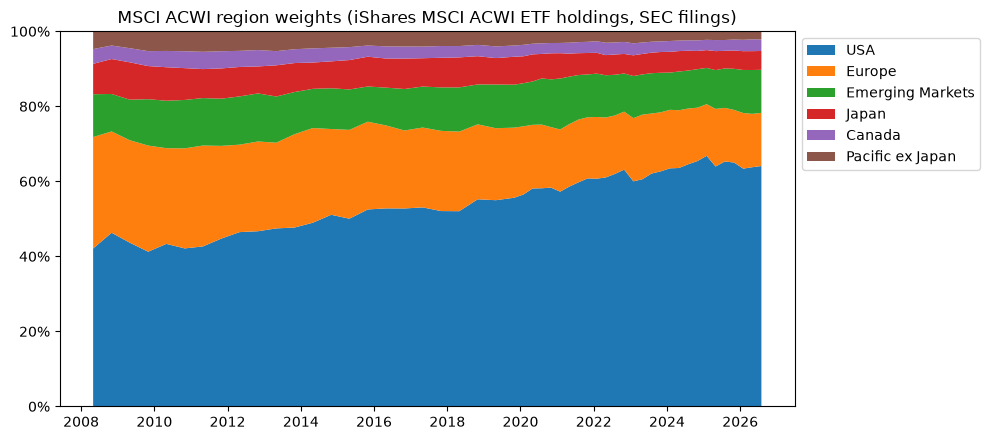

In [10]:
rp = region_prices(prices)
dates = acwi_weights.index
drift_error = pd.Series({
    cur: ((acwi_weights.loc[prev, REGIONS].astype(float) * rp.asof(cur) / rp.asof(prev))
          .pipe(lambda w: w / w.sum()) - acwi_weights.loc[cur, REGIONS].astype(float)).abs().sum() / 2
    for prev, cur in zip(dates[:-1], dates[1:])
}, name="drift error")
print(f"Drift error over one quarter: mean {drift_error.mean():.2%}, max {drift_error.max():.2%} ({drift_error.idxmax().date()})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(dates, acwi_weights[REGIONS].T.astype(float), labels=REGIONS)
ax.set_title("MSCI ACWI region weights (iShares MSCI ACWI ETF holdings, SEC filings)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_acwi_weights.png", dpi=200)
plt.show()

## 3. Backtest
Three portfolios are compared, each starting at 1:
- **Regional Momentum:** the strategy.
- **Passive replica:** the same six ETFs at ACWI weights, without tilt. It shows how well the building
  blocks replicate the index and isolates the contribution of the momentum signal.
- **MSCI ACWI (ACWI ETF):** the benchmark.

At each rebalancing date the signal and the target weights use the closing prices of that day, and the
trades are executed at that close. Between rebalancing dates weights drift with prices.

In [11]:
res = run_all(prices, acwi_weights, rf, PARAMS)
navs, returns, table = res["navs"], res["returns"], res["table"]
print(f"Sample of monthly returns: {returns.index[0]:%b %Y} to {returns.index[-1]:%b %Y} ({len(returns)} months)")
table.to_csv(OUTPUT / "performance_table.csv")
pct = ["Average return p.a.", "Geometric return p.a.", "Volatility p.a.", "Alpha p.a.",
       "Tracking error p.a.", "Max drawdown", "Turnover p.a.", "Trading costs p.a."]
display(table.T.style.format("{:.2%}", subset=pd.IndexSlice[pct, :]).format("{:.2f}", subset=pd.IndexSlice[[i for i in table.columns if i not in pct], :]))

Sample of monthly returns: Jul 2008 to Oct 2026 (220 months)


,Regional Momentum,Passive replica,MSCI ACWI (ACWI ETF)
Average return p.a.,9.18%,9.63%,9.55%
Geometric return p.a.,8.11%,8.62%,8.50%
Volatility p.a.,16.33%,16.21%,16.43%
Sharpe ratio,0.48,0.51,0.50
Alpha p.a.,-0.30%,0.20%,0.00%
Alpha t-stat,-1.03,0.89,nan
Beta,0.99,0.99,1.00
Tracking error p.a.,1.24%,0.97%,0.00%
Information ratio,-0.30,0.08,nan
Max drawdown,-46.22%,-44.91%,-45.80%


**Calculation assumptions.** Monthly returns from month-end values. Average return = arithmetic mean
x 12; volatility = standard deviation x sqrt(12). Sharpe ratio = annualised mean excess return over the
T-bill rate / annualised volatility of excess returns. Alpha and beta from the OLS regression
(r - rf) = alpha + beta (r_ACWI - rf) + e on monthly excess returns; alpha is annualised x 12, beta is not
annualised. Information ratio = annualised mean active return (r - r_ACWI) / tracking error (annualised
standard deviation of active returns). Trading costs are deducted from the portfolio value at each
rebalancing (the initial purchase is not charged).

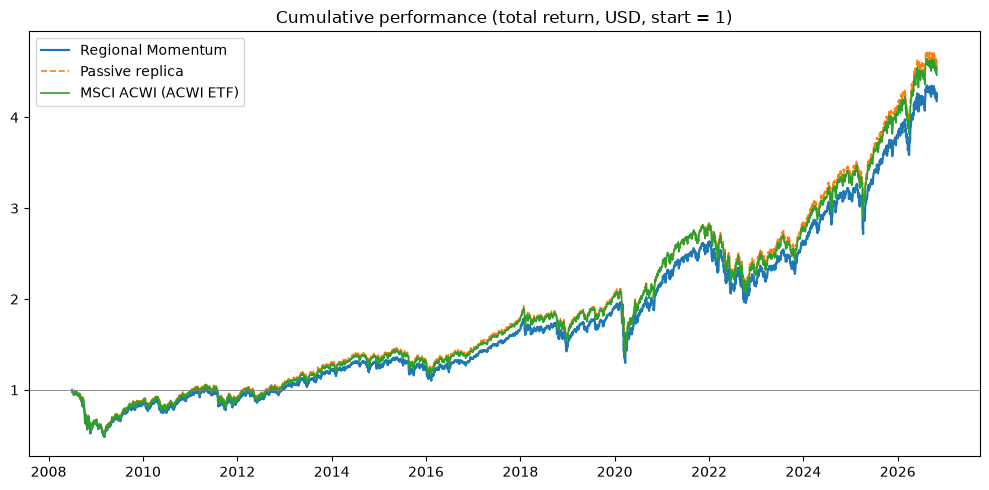

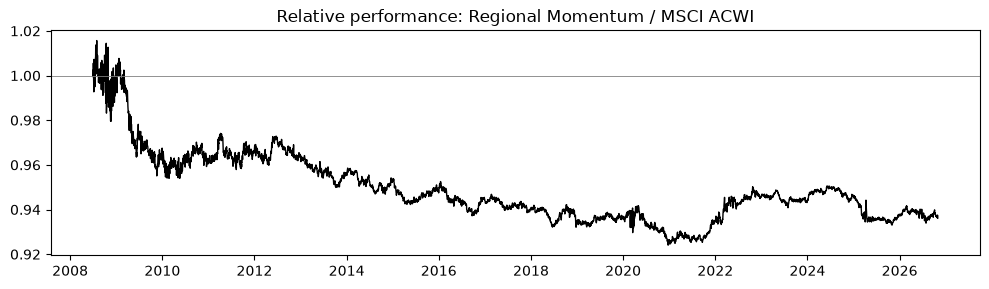

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
for col, style in zip(navs.columns, ["-", "--", "-"]):
    ax.plot(navs.index, navs[col], style, label=col, lw=1.6 if col == "Regional Momentum" else 1.2)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Cumulative performance (total return, USD, start = 1)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "fig_cumulative_performance.png", dpi=200)
plt.show()

active = (navs["Regional Momentum"] / navs["MSCI ACWI (ACWI ETF)"])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(active.index, active, color="black", lw=1)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Relative performance: Regional Momentum / MSCI ACWI")
fig.tight_layout()
fig.savefig(OUTPUT / "fig_relative_performance.png", dpi=200)
plt.show()

### Active weights over time (strategy minus passive replica)

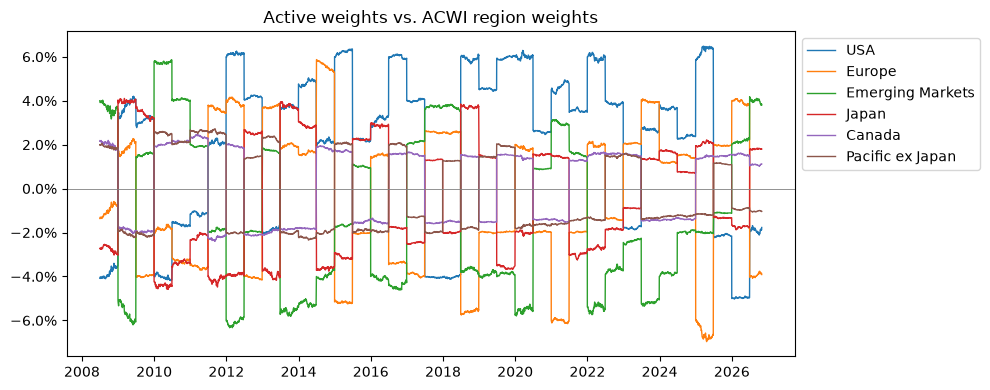

In [13]:
active_w = res["strategy"].weights - res["passive"].weights
fig, ax = plt.subplots(figsize=(10, 4))
for r in REGIONS:
    ax.plot(active_w.index, active_w[r], label=r, lw=1)
ax.axhline(0, color="grey", lw=0.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Active weights vs. ACWI region weights")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_active_weights.png", dpi=200)
plt.show()

### Rebalancing log and an example of the allocation rule (latest rebalancing date)

In [14]:
trades = res["strategy"].trades
trades.to_csv(OUTPUT / "rebalancing_log.csv")
last = trades.iloc[-1]
example = pd.DataFrame({
    "ACWI weight": [last[f"base {r}"] for r in REGIONS],
    f"{PARAMS.lookback_months}m return": [last[f"signal {r}"] for r in REGIONS],
    "Target weight": [last[f"target {r}"] for r in REGIONS],
}, index=REGIONS)
example["Active weight"] = example["Target weight"] - example["ACWI weight"]
example["Rank"] = example[f"{PARAMS.lookback_months}m return"].rank(ascending=False).astype(int)
print(f"Rebalancing on {trades.index[-1].date()}, ACWI weights from holdings as of {last['anchor'].date()}, turnover {last['turnover']:.1%}")
example.to_csv(OUTPUT / "example_rebalancing.csv")
display(example.sort_values("Rank").style.format("{:.2%}", subset=["ACWI weight", f"{PARAMS.lookback_months}m return", "Target weight", "Active weight"]))
display(trades[["anchor", "turnover", "cost"]].style.format({"turnover": "{:.1%}", "cost": "{:.3%}"}))

Rebalancing on 2026-06-30, ACWI weights from holdings as of 2026-04-30, turnover 17.0%


,ACWI weight,12m return,Target weight,Active weight,Rank
Emerging Markets,12.06%,44.59%,16.24%,4.18%,1
Japan,5.08%,29.77%,6.85%,1.77%,2
Canada,2.99%,26.47%,4.03%,1.04%,3
USA,63.76%,22.21%,61.76%,-2.00%,4
Europe,14.12%,18.51%,10.12%,-4.00%,5
Pacific ex Japan,1.99%,11.82%,0.99%,-0.99%,6


,anchor,turnover,cost
date,,,
2008-06-30 00:00:00,2008-04-30 00:00:00,0.0%,0.000%
2008-12-31 00:00:00,2008-10-31 00:00:00,31.7%,0.048%
2009-06-30 00:00:00,2009-04-30 00:00:00,14.2%,0.021%
2009-12-31 00:00:00,2009-10-31 00:00:00,30.3%,0.045%
2010-06-30 00:00:00,2010-04-30 00:00:00,7.2%,0.011%
2010-12-31 00:00:00,2010-10-31 00:00:00,5.8%,0.009%
2011-06-30 00:00:00,2011-04-30 00:00:00,20.5%,0.031%
2011-12-30 00:00:00,2011-10-31 00:00:00,16.1%,0.024%
2012-06-29 00:00:00,2011-10-31 00:00:00,27.8%,0.042%


### Calendar-year returns

In [15]:
annual = navs.resample("YE").last().pct_change()
annual.iloc[0] = navs.resample("YE").last().iloc[0] / navs.iloc[0] - 1  # 2008: from 30 June
annual.index = annual.index.year
annual["Active (vs. ACWI)"] = annual["Regional Momentum"] - annual["MSCI ACWI (ACWI ETF)"]
annual.to_csv(OUTPUT / "annual_returns.csv")
display(annual.style.format("{:.2%}"))
print(f"Strategy beat the ACWI in {(annual['Active (vs. ACWI)'] > 0).sum()} of {len(annual)} calendar years")

,Regional Momentum,Passive replica,MSCI ACWI (ACWI ETF),Active (vs. ACWI)
Date,,,,
2008,-34.44%,-33.08%,-34.40%,-0.04%
2009,27.40%,31.22%,32.36%,-4.96%
2010,12.62%,12.31%,12.78%,-0.16%
2011,-7.35%,-7.15%,-7.82%,0.47%
2012,16.49%,17.14%,16.75%,-0.26%
2013,21.48%,22.35%,22.38%,-0.89%
2014,3.53%,3.80%,3.83%,-0.31%
2015,-2.83%,-2.43%,-2.21%,-0.63%
2016,8.01%,8.48%,8.40%,-0.39%


Strategy beat the ACWI in 5 of 19 calendar years


## 4. Sensitivity analysis
Each row changes one assumption of the base case and keeps everything else fixed.

In [16]:
grid = {
    "rebalance": ["Q", "S", "A"],
    "lookback_months": [6, 12],
    "tilt_pp": [0.0, 3.0, 6.0, 10.0],
    "cost_bps": [0.0, 15.0, 50.0],
}
sens = sensitivity(prices, acwi_weights, rf, PARAMS, grid)
sens.to_csv(OUTPUT / "sensitivity.csv")
display(sens.style.format({c: "{:.2%}" for c in ["Average return p.a.", "Volatility p.a.", "Alpha p.a.", "Turnover p.a."]})
                  .format({c: "{:.2f}" for c in ["Sharpe ratio", "Beta", "Information ratio"]}))

## 5. Consistency with the Streamlit app
The app imports the same functions from `regional_momentum/core.py`. With its default settings it must
show the numbers below.

In [17]:
default_metrics = table.round(6).to_dict(orient="index")
(OUTPUT / "default_metrics.json").write_text(json.dumps({"params": PARAMS.__dict__, "metrics": default_metrics}, indent=2))
pd.DataFrame(default_metrics).T[["Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta", "Information ratio"]]

,Average return p.a.,Volatility p.a.,Sharpe ratio,Alpha p.a.,Beta,Information ratio
Regional Momentum,0.0918,0.1633,0.4776,-0.0030,0.9912,-0.3002
Passive replica,0.0963,0.1621,0.5089,0.0020,0.9852,0.0800
MSCI ACWI (ACWI ETF),0.0955,0.1643,0.4974,0.0000,1.0000,NaN
